# Classification Metrics from Scratch

## Objectives
- Implement a confusion matrix from scratch.
- Calculate accuracy, precision, recall, specificity, and F1-score.
- Understand sensitivity and false-positive rate.
- Calculate ROC curve and AUC.
- Validate the implementations against Scikit-Learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

In [2]:
X, y = make_classification(
    n_samples=1000,
    n_features=6,
    n_informative=4,
    n_redundant=2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Test samples:", len(y_test))
print("Predictions generated successfully.")

Test samples: 200
Predictions generated successfully.


In [3]:
def confusion_matrix_scratch(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if y_true.shape != y_pred.shape:
        raise ValueError("y_true and y_pred must have the same shape.")

    if not np.all(np.isin(y_true, [0, 1])) or not np.all(np.isin(y_pred, [0, 1])):
        raise ValueError("This implementation requires binary labels 0 and 1.")

    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    return np.array([[tn, fp], [fn, tp]])

cm = confusion_matrix_scratch(y_test, y_pred)

print("Confusion Matrix:")
print(cm)
print("\nTN, FP, FN, TP:", cm.ravel())

Confusion Matrix:
[[75 25]
 [35 65]]

TN, FP, FN, TP: [75 25 35 65]


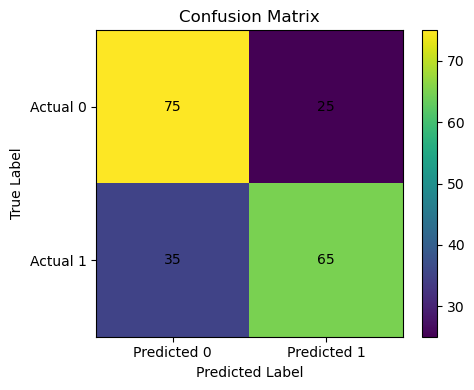

In [4]:
plt.figure(figsize=(5, 4))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["Predicted 0", "Predicted 1"])
plt.yticks([0, 1], ["Actual 0", "Actual 1"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [5]:
def classification_metrics_scratch(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix_scratch(y_true, y_pred).ravel()

    safe_divide = lambda a, b: a / b if b != 0 else 0.0

    accuracy = safe_divide(tp + tn, tp + tn + fp + fn)
    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)
    specificity = safe_divide(tn, tn + fp)
    f1 = safe_divide(2 * precision * recall, precision + recall)
    false_positive_rate = safe_divide(fp, fp + tn)

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall / Sensitivity": recall,
        "Specificity": specificity,
        "F1-score": f1,
        "False Positive Rate": false_positive_rate
    }

scratch_metrics = classification_metrics_scratch(y_test, y_pred)

pd.Series(scratch_metrics).to_frame("Score").round(4)

,Score
Accuracy,0.7000
Precision,0.7222
Recall / Sensitivity,0.6500
Specificity,0.7500
F1-score,0.6842
False Positive Rate,0.2500


In [6]:
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

sklearn_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall / Sensitivity": recall_score(y_test, y_pred, zero_division=0),
    "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "False Positive Rate": fp / (fp + tn) if (fp + tn) else 0.0
}

comparison = pd.DataFrame({
    "Scratch": scratch_metrics,
    "Scikit-Learn": sklearn_metrics
})

comparison["Absolute Difference"] = (
    comparison["Scratch"] - comparison["Scikit-Learn"]
).abs()

comparison.round(6)

,Scratch,Scikit-Learn,Absolute Difference
Accuracy,0.700000,0.700000,0.0
Precision,0.722222,0.722222,0.0
Recall / Sensitivity,0.650000,0.650000,0.0
Specificity,0.750000,0.750000,0.0
F1-score,0.684211,0.684211,0.0
False Positive Rate,0.250000,0.250000,0.0


AUC (from ROC curve): 0.7685
AUC (Scikit-Learn):   0.7685


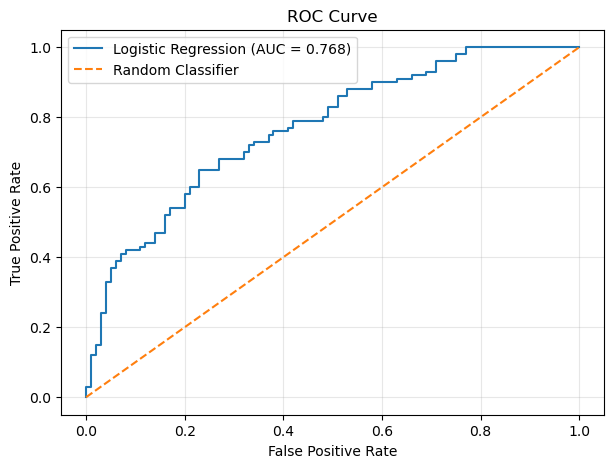

In [7]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_scratch = np.trapezoid(tpr, fpr)
auc_sklearn = roc_auc_score(y_test, y_prob)

print(f"AUC (from ROC curve): {auc_scratch:.4f}")
print(f"AUC (Scikit-Learn):   {auc_sklearn:.4f}")

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_sklearn:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
thresholds_to_test = np.arange(0.1, 1.0, 0.1)
threshold_results = []

for threshold in thresholds_to_test:
    threshold_pred = (y_prob >= threshold).astype(int)
    metrics = classification_metrics_scratch(y_test, threshold_pred)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall / Sensitivity"],
        "F1-score": metrics["F1-score"]
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(4)

,Threshold,Precision,Recall,F1-score
0,0.1,0.5102,1.00,0.6757
1,0.2,0.5495,1.00,0.7092
2,0.3,0.5909,0.91,0.7165
3,0.4,0.6423,0.79,0.7085
4,0.5,0.7222,0.65,0.6842
5,0.6,0.7460,0.47,0.5767
6,0.7,0.8667,0.39,0.5379
7,0.8,0.8800,0.22,0.3520
8,0.9,0.8000,0.04,0.0762


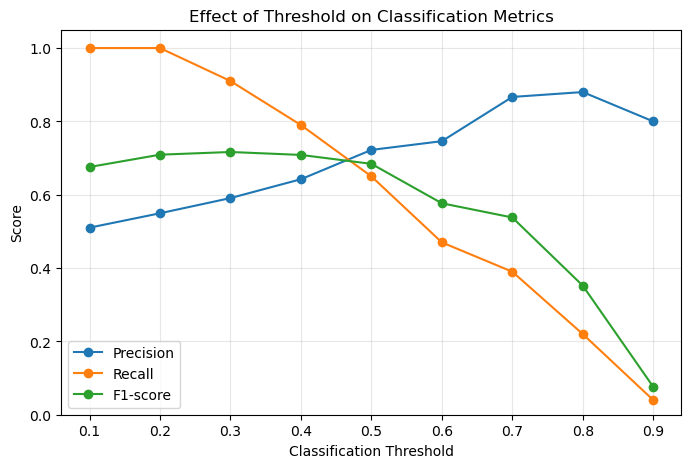

In [9]:
plt.figure(figsize=(8, 5))

for metric in ["Precision", "Recall", "F1-score"]:
    plt.plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Effect of Threshold on Classification Metrics")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Key Takeaways

- The confusion matrix reveals false positives and false negatives.
- Accuracy can be misleading on imbalanced datasets.
- Precision matters when false-positive predictions are costly.
- Recall matters when missing positive cases is costly.
- Specificity measures how well negative cases are identified.
- ROC-AUC evaluates ranking performance across classification thresholds.
- The best threshold depends on the problem and its error costs.